# Spin Hall conductivity of the Kane–Mele model

In this tutorial you compute the spin–orbit gap and the quantised spin Hall conductivity (SHC) of the Kane–Mele model. The Kane–Mele model is graphene with spin–orbit coupling, and the first model of a quantum spin Hall insulator. PAOFLOW builds its tight-binding Hamiltonian $H_{\alpha\beta}(\mathbf{R})$ from four parameters, in contrast to the DFT Hamiltonian of the [bands and DOS tutorial](tutorial01.ipynb). Every result therefore has an analytic value to check against before you trust the same calls on a material. The method is {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.spin_Hall`, called after the steps of the bands and DOS tutorial from `bands()` to `dos()`.

**What you will compute**

- The spin–orbit gap of the Kane–Mele model, and the filling at which the energy zero lies in it
- The spin Hall conductivity as a function of energy, and its quantised plateau inside the gap
- How the broadening of the Kubo formula lowers the plateau
- The spin Berry curvature of the occupied bands in the Brillouin zone, and how it adds up to the plateau

:::{tip}
This page is built on the case [`kane_mele_tb_model`](https://github.com/marcobn/PAOFLOW/tree/develop/examples/cases/kane_mele_tb_model): open it in PAOFLOW Studio with *Examples…* → `kane_mele_tb_model`, or copy it with `paoflow-gen --example kane_mele_tb_model`. The notebook runs in about 10 s on one core. To change the parameters of the model, or try the same calls on a model of your own, {download}`download this notebook <tutorial05.ipynb>`. The model is built in code, so the notebook downloads no input and has no setup cell. This tutorial assumes the [bands and DOS tutorial](tutorial01.ipynb), and [How to run PAOFLOW on a tight-binding model](../howtos/tight-binding-model.md) for how a model replaces the DFT steps.
:::

## Required input

This tutorial has no DFT input. You pass the model as a dictionary to the `model` argument of `PAOFLOW`, with its parameters in eV. PAOFLOW builds $H_{\alpha\beta}(\mathbf{R})$ from it, in place of the projection steps of the bands and DOS tutorial. [Choosing the model](../howtos/tight-binding-model.md#choosing-the-model) lists the built-in models and their parameters.

## The Kane–Mele model and its spin–orbit gap

You start from the model of [C. L. Kane and E. J. Mele, Phys. Rev. Lett. 95, 226801 (2005)](https://doi.org/10.1103/PhysRevLett.95.226801): graphene with one orbital per site and both spins. Spin–orbit coupling enters as a spin-dependent hopping between second neighbours:

$$
H = t \sum_{\langle ij \rangle} c_i^\dagger c_j
  + i\lambda_{SO} \sum_{\langle\langle ij \rangle\rangle} \nu_{ij}\, c_i^\dagger \sigma_z c_j
  + t\, v \sum_i \xi_i\, c_i^\dagger c_i
  + H_R ,
$$

| Symbol | Argument | Meaning |
| --- | --- | --- |
| $t$ | `t` | first-neighbour hopping |
| $\lambda_{SO}$ | `soc_par` | spin–orbit hopping between second neighbours |
| $v$ | `v_par` | sublattice potential, in units of $t$ |
| $H_R$ | `r_par` | Rashba term, which mixes the two spins |
| $\sigma_z$ | | Pauli matrix of the spin |
| $\xi_i$ | | $\pm 1$ on the two sublattices |
| $\nu_{ij}$ | | $\pm 1$, depending on whether the path from $j$ to $i$ through their common neighbour turns left or right |

With `r_par=0` and `v_par=0`, as here, $\sigma_z$ is conserved. The model then splits into two spinless honeycomb models, one per spin, whose second-neighbour hoppings $\pm i\lambda_{SO}$ have opposite signs. Each of them is a Haldane model with a gap $6\sqrt{3}\,\lambda_{SO}$ at $K$ and $K'$ ([The quantum spin Hall model of Kane and Mele](../theory/berry-topology.md#the-quantum-spin-hall-model-of-kane-and-mele)).

The cell below builds the model with $t = 1$ eV and $\lambda_{SO} = 0.1$ eV and computes its bands. The lattice is a honeycomb plane without hopping along $z$. You therefore give the path in crystal coordinates of the two in-plane reciprocal vectors $\mathbf{b}_1$ and $\mathbf{b}_2$, with $K = (\tfrac23, \tfrac13)$, and interpolate on a $60 \times 60$ mesh with a single k-point along $z$ (`nfft3=1`).

The band energies, velocities and DOS on that mesh are computed as in the bands and DOS tutorial, with one change. On the mesh of a model the band velocity vanishes exactly at $\Gamma$, $M$ and $K$, and with it the adaptive width ([Band velocities and adaptive smearing](tutorial01.ipynb#band-velocities-and-adaptive-smearing)). Set a floor on the adaptive widths with `min_width=0.02` eV, twice the spacing of the DOS energy grid.

In [1]:
import numpy as np
from PAOFLOW import PAOFLOW

model = {'label': 'Kane_Mele', 't': 1.0, 'soc_par': 0.1, 'r_par': 0.0, 'v_par': 0.0}
paoflow = PAOFLOW.PAOFLOW(model=model, outputdir='kane_mele', verbose=False)

points = {'G': [0.0, 0.0, 0.0], 'M': [0.5, 0.0, 0.0], 'K': [2 / 3, 1 / 3, 0.0]}
paoflow.bands(ibrav=4, nk=100, band_path='G-M-K-G', high_sym_points=points)

paoflow.interpolated_hamiltonian(nfft1=60, nfft2=60, nfft3=1)
paoflow.pao_eigh()
paoflow.gradient_and_momenta()
paoflow.adaptive_smearing(min_width=0.02)
paoflow.dos(emin=-3.5, emax=3.5, ne=701, do_pdos=False)

bands = np.loadtxt('kane_mele/bands_0.dat')[:, 1:]
gap = bands[:, 2].min() - bands[:, 1].max()  # four bands, each twofold degenerate
print(f'gap {gap:.4f} eV between {bands[:, 1].max():.3f} and {bands[:, 2].min():.3f} eV')
print(f'6 sqrt(3) lambda_SO = {6 * np.sqrt(3) * 0.1:.4f} eV')
energy, dos = np.loadtxt('kane_mele/dosdk_0.dat', unpack=True)
print(f'states below E = 0: {np.trapezoid(dos[energy <= 0], energy[energy <= 0]):.2f}')


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.025 sec


Bands in:                                   0.099 sec


New estimated maximum array size: 0.01 GBytes
R -> k with Zero Padding in:                0.918 sec


Eigenvalues in:                             2.045 sec


Gradient in:                                0.818 sec


Momenta in:                                 3.664 sec


Adaptive Smearing in:                       0.018 sec


DoS (Adaptive Smearing) in:                 1.404 sec


gap 1.0392 eV between -0.520 and 0.520 eV
6 sqrt(3) lambda_SO = 1.0392 eV
states below E = 0: 2.00


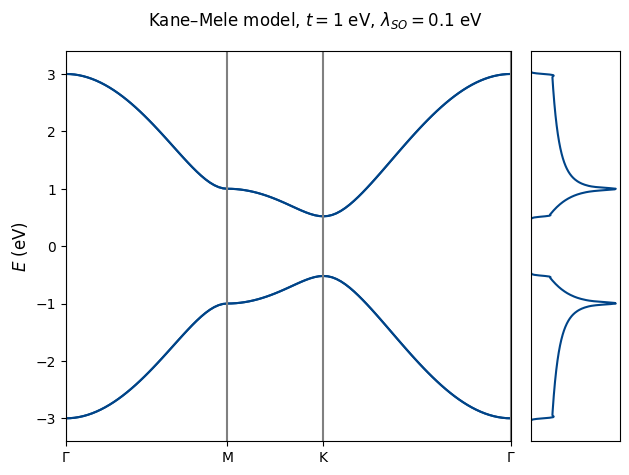

In [2]:
from PAOFLOW import GPAO

GPAO.GPAO().plot_dos_beside_bands(
    'kane_mele/dosdk_0.dat',
    'kane_mele/bands_0.dat',
    sym_points='kane_mele/kpath_points.txt',
    title=r'Kane–Mele model, $t = 1$ eV, $\lambda_{SO} = 0.1$ eV',
    band_label=r'$E$ (eV)',
    y_lim=(-3.4, 3.4),
    col='#004488',
)

Each band is twofold degenerate, because the model has both time-reversal and inversion symmetry. The spin–orbit term opens a gap of 1.0392 eV at $K$, equal to $6\sqrt{3}\,\lambda_{SO}$. Without spin–orbit coupling the bands would touch at $K$, as in graphene.

A model has no electron count of its own, and its energy zero is the zero of its on-site energies. The DOS integrates to 2.00 states below $E = 0$, two of the four bands. $E = 0$ therefore lies in the gap of the half-filled model, which is the filling of graphene.

The gap alone does not say whether the occupied bands differ from those of a trivial insulator. Their spin Berry curvature, which you compute next, does.

## The spin Hall conductivity and its plateau in the gap

You now compute the spin Hall conductivity $\sigma^z_{xy}$: the current of spin $s_z$ along $x$ driven by an electric field along $y$. `spin_Hall()` evaluates the Kubo formula as a sum over states of the spin Berry curvature ([Spin Berry curvature and spin Hall conductivity](../theory/berry-topology.md#spin-berry-curvature-and-spin-hall-conductivity)):

$$
\Omega^z_{n}(\mathbf{k}) = -2 \sum_{m \ne n}
  \frac{\mathrm{Im}\bigl[j^{z}_{x,nm}(\mathbf{k})\, v^y_{mn}(\mathbf{k})\bigr]}
       {(\varepsilon_{n\mathbf{k}} - \varepsilon_{m\mathbf{k}})^2 + \delta^2} ,
\qquad
\sigma^z_{xy}(E) = \frac{1}{N_\mathrm{mesh} A} \sum_{\mathbf{k}} \sum_n f_{n\mathbf{k}}(E)\, \Omega^z_{n}(\mathbf{k}) ,
$$

| Symbol | Meaning |
| --- | --- |
| $v^i = \partial H / \partial k_i$ | velocity matrices of the bands and DOS tutorial, in the band basis |
| $j^z_x = \tfrac12\{s_z, v^x\}$ | spin current, with $s_z = \sigma_z/2$ |
| $f_{n\mathbf{k}}(E)$ | occupation at Fermi energy $E$, with the adaptive Gaussian widths of the first step |
| $A$ | area of the cell, in bohr$^2$ |
| $\delta$ | broadening, `delta` (default 0.05 eV) |

Two details keep the sum well defined. Pairs whose denominator is below $10^{-4}$ eV$^2$ are left out. Each degenerate pair, here the two spin partners of a band, is first rotated to the basis that diagonalises $j^z_x$. The result then does not depend on how the computed eigenvectors mix the pair ([Degenerate bands](../theory/berry-topology.md#degenerate-bands)).

With `twoD=True` the sum is divided by the area instead of the volume, and is not multiplied by $e^2/\hbar$. `shcEf_z_xy.dat` therefore holds a dimensionless sheet conductivity in units with $\hbar = e = 1$, not a value in $\Omega^{-1}$. In these units the quantum of the spin Hall conductivity, $e/2\pi$, is $1/2\pi = 0.159155$.

The broadening $\delta$ keeps the denominators finite where two bands nearly touch. The price is that it lowers every term by the factor $(\varepsilon_{n\mathbf{k}} - \varepsilon_{m\mathbf{k}})^2/[(\varepsilon_{n\mathbf{k}} - \varepsilon_{m\mathbf{k}})^2 + \delta^2]$ ([Berry curvature from the Kubo formula](../theory/berry-topology.md#berry-curvature-from-the-kubo-formula)). The run below therefore computes the plateau for two values of $\delta$.

The result rests on two approximations ([Approximations and their limits](../theory/berry-topology.md#approximations-and-their-limits)). It is the intrinsic conductivity of independent electrons in the clean limit. It uses the conventional spin current $\tfrac12\{s_z, v^x\}$, which is the current of a conserved spin only because `r_par=0`.

The other arguments of the call select the tensor component and the energies:

| Argument | Here | What it sets |
| --- | --- | --- |
| `s_tensor` | `[[0, 1, 2]]` | current along $x$, field along $y$, spin along $z$ |
| `emin`, `emax` | $-4$ and 4 eV | the scan of the Fermi energy, which spans all four bands and so covers every filling of the model |
| `fermi_dw`, `fermi_up` | $-4$ and 0 eV | the energy window of the k-resolved curvature, used in the next section |

In [3]:
for delta in (0.005, 0.05):  # the default 0.05 eV last: its files are plotted below
    paoflow.spin_Hall(
        twoD=True,
        emin=-4.0,
        emax=4.0,
        s_tensor=[[0, 1, 2]],
        delta=delta,
        fermi_dw=-4.0,  # below the lowest band: the curvature map sums all occupied bands
        fermi_up=0.0,
    )
    energy, shc = np.loadtxt('kane_mele/shcEf_z_xy.dat', unpack=True)
    print(f'delta = {delta} eV: sigma at E = 0: {shc[np.abs(energy).argmin()]:.6f}')
print(f'1/2pi = {1 / (2 * np.pi):.6f}')

Spin Hall Conductivity in:                 14.601 sec


delta = 0.005 eV: sigma at E = 0: 0.159153


Spin Hall Conductivity in:                  2.875 sec


delta = 0.05 eV: sigma at E = 0: 0.158987
1/2pi = 0.159155


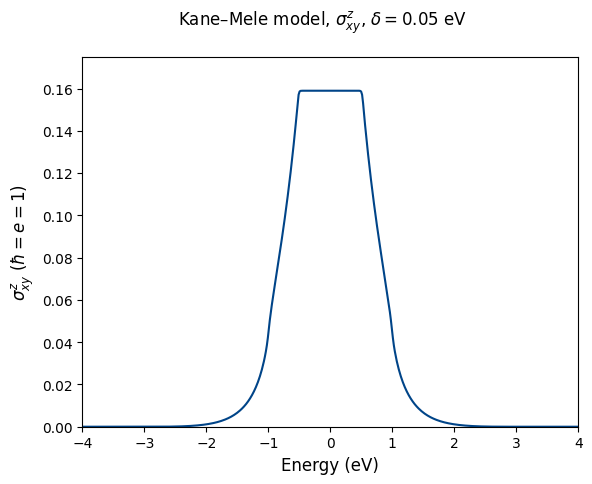

In [4]:
from PAOFLOW import GPAO

GPAO.GPAO().plot_shc(
    'kane_mele/shcEf_z_xy.dat',
    title=r'Kane–Mele model, $\sigma^z_{xy}$, $\delta = 0.05$ eV',
    x_lim=(-4.0, 4.0),
    cols='#004488',
    label=r'$\sigma^z_{xy}$ ($\hbar = e = 1$)',
)

Inside the gap, $\sigma^z_{xy}$ is constant at 0.158987, because moving $E$ through the gap does not change the occupied states ([Chern number and the quantised plateau](../theory/berry-topology.md#chern-number-and-the-quantised-plateau)). This plateau lies 0.1% below $1/2\pi$. The default broadening adds $\delta^2$ to denominators of the order of the gap squared, and so lowers the plateau slightly. With $\delta = 0.005$ eV the plateau is 0.159153, equal to $1/2\pi$ to five digits. For a quantised result, choose $\delta$ much smaller than the gap.

Outside the gap the conductivity falls as $E$ enters the bands. It vanishes below $-3$ eV, where every band is empty, and above 3 eV, where every band is full and the curvatures of all bands add up to zero.

## The spin Berry curvature in the Brillouin zone

The plateau is a sum over the whole zone, and a map of its terms shows where the curvature sits. `spin_Hall()` writes this map to `Spin_Berry_z_xy.bxsf`, on the mesh and in bohr$^2$. It holds the k-resolved curvature $\sum_n [f_{n\mathbf{k}}(E_\mathrm{up}) - f_{n\mathbf{k}}(E_\mathrm{dw})]\,\Omega^z_n(\mathbf{k})$, with $E_\mathrm{dw}$ = `fermi_dw` and $E_\mathrm{up}$ = `fermi_up`.

The defaults, $\mp 1$ eV, keep only the states near the gap. Here `fermi_dw=-4.0` lies below the lowest band and `fermi_up=0.0` in the gap, so the map holds the curvature of all occupied bands. Its average divided by $A$ is then the plateau. The file is that of the last run, with $\delta = 0.05$ eV. The cell below reads the map, which needs no further PAOFLOW call, and draws it over one reciprocal cell.

spin Berry curvature: largest 4.95 bohr^2, average 0.4917 bohr^2
average / cell area (3.0926 bohr^2) = 0.158987


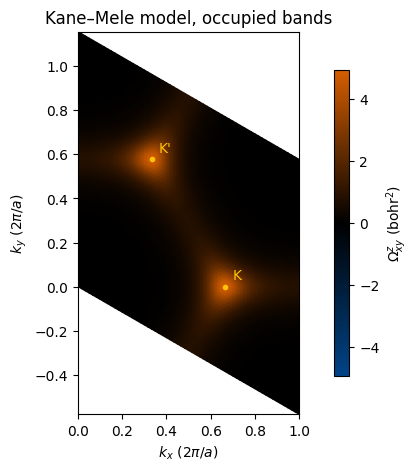

In [5]:
import contextlib
import io

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from PAOFLOW.gen.fermi_plotter import read_fermi_bxsf

cmap = LinearSegmentedColormap.from_list('palette', ['#004488', '#000000', '#D55E00'])
recip = np.array([[1.0, -1 / np.sqrt(3)], [0.0, 2 / np.sqrt(3)]])  # b1, b2 of the cell (2 pi / a)

with contextlib.redirect_stdout(io.StringIO()):  # the reader reports the two identical bands
    spin_berry = read_fermi_bxsf('kane_mele/Spin_Berry_z_xy.bxsf')
n1, n2, _ = spin_berry.dims
omega = spin_berry.bands[1][:, :, 0]  # bohr^2; the grid repeats its first point at the end
grid = np.stack(np.meshgrid(np.linspace(0, 1, n1), np.linspace(0, 1, n2), indexing='ij'), axis=-1)
area = np.sqrt(3) / 2 * 1.8897261**2  # the Kane-Mele cell: a = 1 Angstrom, in bohr^2
mean = omega[:-1, :-1].mean()
print(f'spin Berry curvature: largest {omega.max():.2f} bohr^2, average {mean:.4f} bohr^2')
print(f'average / cell area ({area:.4f} bohr^2) = {mean / area:.6f}')

k = grid @ recip
fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
vmax = np.abs(omega).max()
mesh = ax.pcolormesh(
    k[..., 0], k[..., 1], omega, cmap=cmap, vmin=-vmax, vmax=vmax, shading='gouraud'
)
for name, point in (('K', [2 / 3, 1 / 3]), ("K'", [1 / 3, 2 / 3])):
    x, y = np.array(point) @ recip
    ax.plot(x, y, '.', color='#FFC20A', ms=6)
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords='offset points', color='#FFC20A')
ax.set_aspect('equal')
ax.set_title('Kane–Mele model, occupied bands')
ax.set_xlabel(r'$k_x$ ($2\pi/a$)')
ax.set_ylabel(r'$k_y$ ($2\pi/a$)')
fig.colorbar(mesh, ax=ax, label=r'$\Omega^z_{xy}$ (bohr$^2$)', shrink=0.8)
plt.show()

The map covers one reciprocal cell, the parallelogram spanned by $\mathbf{b}_1$ and $\mathbf{b}_2$. The spin Berry curvature peaks at $K$ and $K'$ with the same sign, up to 4.95 bohr$^2$, and is close to zero elsewhere.

The decomposition of the model by spin explains this. Each spin is a Haldane model, whose complex second-neighbour hopping gives its Berry curvature the same sign at both valleys. The phase of that hopping has the sign of the spin, so the two spins have opposite Chern numbers, $C_\uparrow = -C_\downarrow = \pm 1$. Their charge Hall conductivities cancel, and their spin Hall conductivities add. With $s_z = \pm\tfrac12$ the plateau is $(C_\uparrow - C_\downarrow)/4\pi = 1/2\pi$ in these units ([Spin Berry curvature and spin Hall conductivity](../theory/berry-topology.md#spin-berry-curvature-and-spin-hall-conductivity)).

The map confirms this numerically. Its average, 0.4917 bohr$^2$, divided by the area of the cell, 3.0926 bohr$^2$, gives 0.15899, the plateau of the spin Hall conductivity at the same $\delta$.

A model with time reversal and without spin–orbit coupling, such as graphene with a sublattice potential, has curvature of opposite signs at $K$ and $K'$ instead. Its Chern number is zero, as the [Berry phase tutorial](tutorial06.ipynb) computes from the Berry flux through the zone. With a Rashba term (`r_par`), $s_z$ is not conserved and the plateau departs from $1/2\pi$. The $\mathbb{Z}_2$ invariant then characterises the phase instead ([The quantum spin Hall model of Kane and Mele](../theory/berry-topology.md#the-quantum-spin-hall-model-of-kane-and-mele)).

## Where to go next

- [Berry curvature and topological invariants](../theory/berry-topology.md) derives the curvature, the Chern number and the Hall conductivities used here, works out the Kane–Mele model, and says where the approximations fail.
- [Berry phases and Chern number of gapped graphene](tutorial06.ipynb) computes the Berry phases and the Chern number of gapped graphene with `berry_phase()`.
- [How to run PAOFLOW on a tight-binding model](../howtos/tight-binding-model.md) lists the other built-in models, and how to build a Slater–Koster model with your own parameters or pass a PythTB model of your own.
- The case [`kane_mele_nlo_model`](https://github.com/marcobn/PAOFLOW/tree/develop/examples/cases/kane_mele_nlo_model) computes the shift current of the same model across its topological transition.
- {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.spin_Hall` lists all arguments, including the projection of the spin current on a set of orbitals (`shc_proj`).

In [6]:
# The numbers the tutorial quotes, at the precision it quotes them.
km = np.loadtxt('kane_mele/bands_0.dat')[:, 1:]
km_gap = km[:, 2].min() - km[:, 1].max()
assert abs(km_gap - 1.0392) < 1e-4, f'Kane-Mele gap {km_gap:.4f} eV'

energy, dos = np.loadtxt('kane_mele/dosdk_0.dat', unpack=True)
below = np.trapezoid(dos[energy <= 0], energy[energy <= 0])
assert abs(below - 2.00) < 0.005, f'states below E = 0: {below:.3f}'

energy, shc = np.loadtxt('kane_mele/shcEf_z_xy.dat', unpack=True)
plateau = shc[np.abs(energy) < 0.3]
assert np.all(
    np.abs(plateau - 0.158987) < 2e-6
), f'SHC plateau {plateau.min():.6f}..{plateau.max():.6f}'

assert abs(omega.max() - 4.95) < 0.005, f'largest spin Berry curvature {omega.max():.3f} bohr^2'
assert abs(mean / area - 0.15899) < 1e-5, f'average spin Berry curvature / area {mean / area:.6f}'